Rows, columns: (891, 12)
Survival rate: 38.4%

Model accuracy on test data:
  Logistic Regression    81.0%
  Decision Tree          79.9%
  Random Forest          81.0%

Best model: Logistic Regression
Confusion matrix [TN FP] [FN TP]:
[[91 14]
 [20 54]]

Classification report:
              precision    recall  f1-score   support

        Died       0.82      0.87      0.84       105
    Survived       0.79      0.73      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179

Feature importance (Random Forest):
  Sex          0.276
  Fare         0.273
  Age          0.259
  Pclass       0.082
  FamilySize   0.079
  Embarked     0.031
New passenger (3rd class, male, 22): Died
New passenger (1st class, female, 30): Survived

Charts saved in: /content
Created: accuracy_comparison.png, confusion_matrix.png, feature_importance.png
1. Model Accuracy Comparison


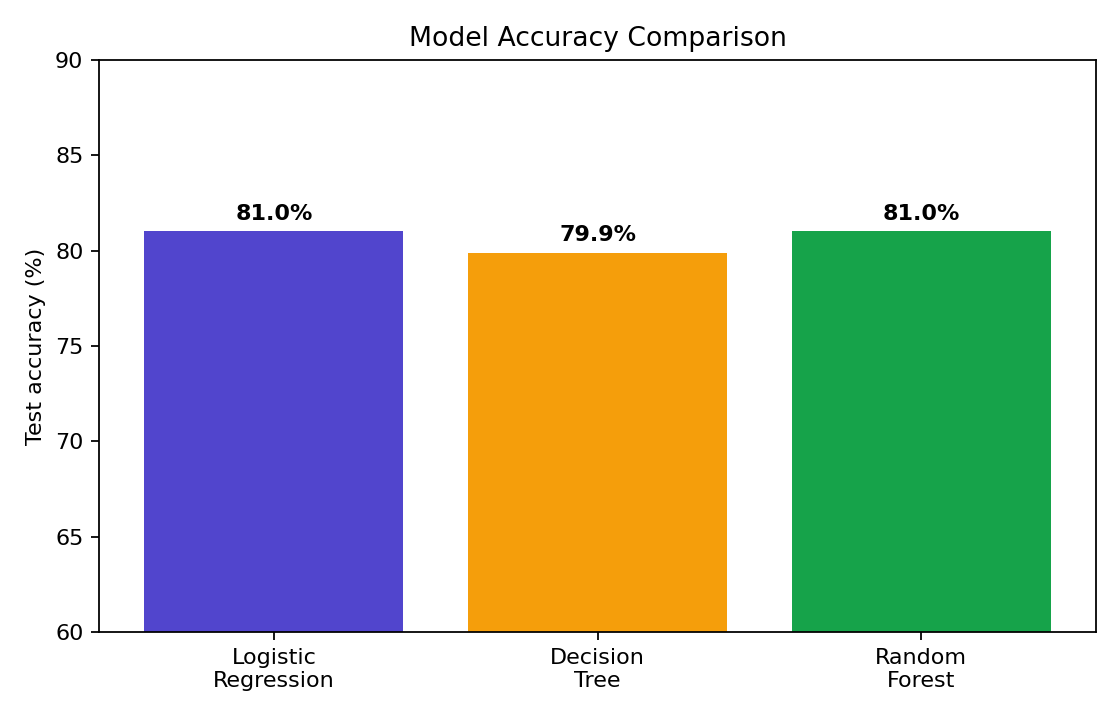

2. Confusion Matrix


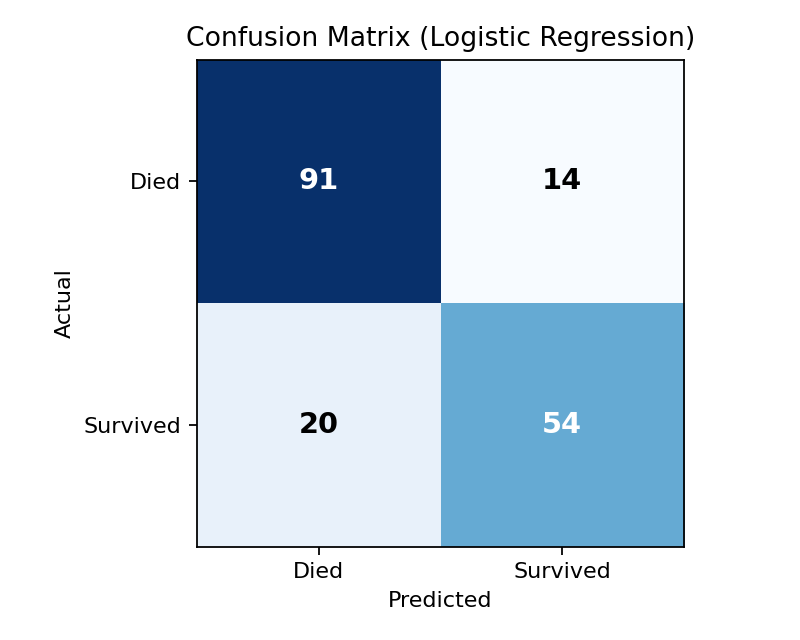

3. Feature Importance


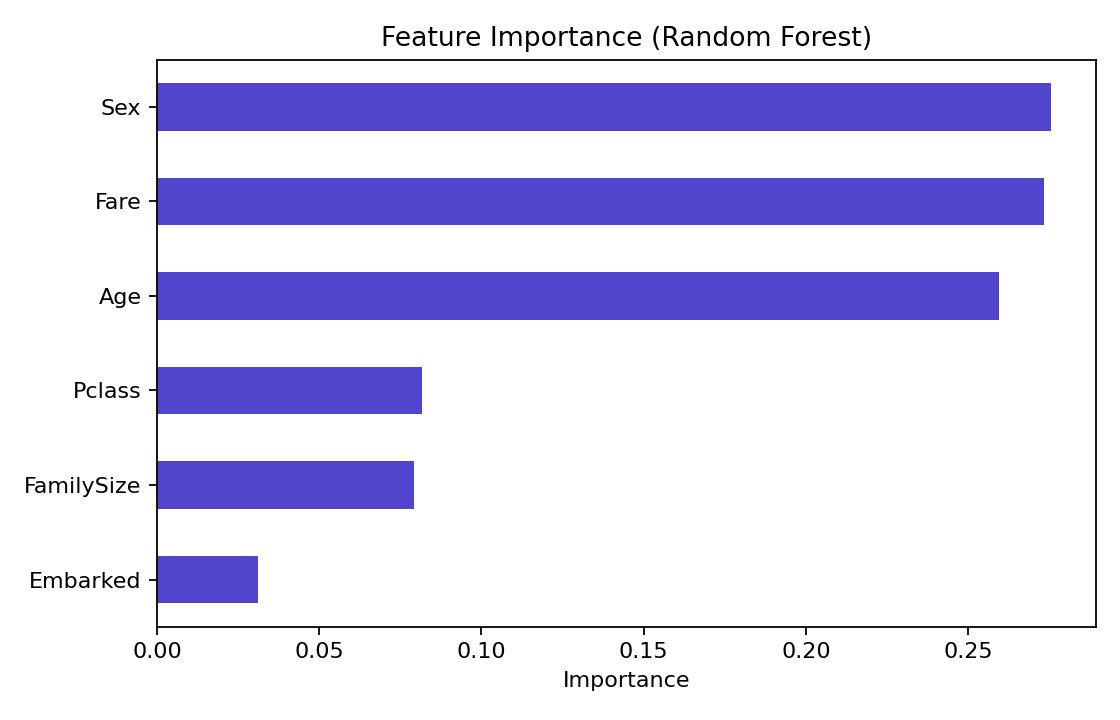

In [3]:
"""
Titanic Survival Prediction using Machine Learning
Run: python titanic_survival.py

Uses the standard 891-row Titanic training dataset. If titanic.csv exists beside
this script it is used; otherwise the script downloads it from a public raw URL.
"""
from pathlib import Path
import urllib.request
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
BASE_DIR = Path("/content")
DATA_FILE = BASE_DIR / "titanic.csv"
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

def load_data():
    if not DATA_FILE.exists():
        print("Downloading Titanic dataset...")
        try:
            urllib.request.urlretrieve(DATA_URL, DATA_FILE)
        except Exception as exc:
            raise RuntimeError(
                "Could not download titanic.csv. Download the Kaggle Titanic train.csv, "
                "rename it titanic.csv, and place it beside this script."
            ) from exc
    df = pd.read_csv(DATA_FILE)
    required = {"Survived", "Pclass", "Sex", "Age", "Fare", "Embarked", "SibSp", "Parch"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Dataset is missing required columns: {sorted(missing)}")
    return df

def main():
    df = load_data()
    print(f"Rows, columns: {df.shape}")
    print(f"Survival rate: {df['Survived'].mean() * 100:.1f}%")

    # Data preprocessing and feature engineering
    df["Age"] = df["Age"].fillna(df["Age"].median())
    df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
    df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
    df["Embarked"] = df["Embarked"].map({"S": 0, "C": 1, "Q": 2})
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    features = ["Pclass", "Sex", "Age", "Fare", "Embarked", "FamilySize"]
    X = df[features].copy()
    y = df["Survived"].astype(int)

    # Fixed split makes results reproducible.
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    }

    fitted = {}
    accuracies = {}
    print("\nModel accuracy on test data:")
    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        fitted[name] = model
        accuracies[name] = accuracy_score(y_test, pred)
        print(f"  {name:<22} {accuracies[name] * 100:.1f}%")

    # max() preserves insertion order on ties, so Logistic Regression wins a tie.
    best_name = max(accuracies, key=accuracies.get)
    best_model = fitted[best_name]
    y_pred = best_model.predict(X_test)

    print(f"\nBest model: {best_name}")
    print("Confusion matrix [TN FP] [FN TP]:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification report:")
    print(classification_report(
        y_test, y_pred, labels=[0, 1], target_names=["Died", "Survived"], digits=2
    ))

    # Feature importance from Random Forest
    rf = fitted["Random Forest"]
    importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
    print("Feature importance (Random Forest):")
    for feature, value in importance.items():
        print(f"  {feature:<12} {value:.3f}")

    # Example passengers use the same six features and encodings as training data.
    new_passengers = pd.DataFrame([
        {"Pclass": 3, "Sex": 0, "Age": 22, "Fare": 7.25, "Embarked": 0, "FamilySize": 1},
        {"Pclass": 1, "Sex": 1, "Age": 30, "Fare": 100.00, "Embarked": 1, "FamilySize": 1},
    ])
    labels = {0: "Died", 1: "Survived"}
    for _, passenger in new_passengers.iterrows():
        prediction = best_model.predict(passenger.to_frame().T)[0]
        description = (
            f"{int(passenger['Pclass'])}{'st' if passenger['Pclass'] == 1 else 'nd' if passenger['Pclass'] == 2 else 'rd'} class, "
            f"{'female' if passenger['Sex'] == 1 else 'male'}, {int(passenger['Age'])}"
        )
        print(f"New passenger ({description}): {labels[prediction]}")

    # Save visualizations
    names = list(accuracies.keys())
    values = [accuracies[n] * 100 for n in names]
    plt.figure(figsize=(7, 4.5))
    bars = plt.bar(["Logistic\nRegression", "Decision\nTree", "Random\nForest"],
                   values, color=["#5145CD", "#F59E0B", "#16A34A"])
    plt.title("Model Accuracy Comparison")
    plt.ylabel("Test accuracy (%)")
    plt.ylim(60, 90)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width()/2, value + 0.4, f"{value:.1f}%",
                 ha="center", va="bottom", fontweight="bold")
    plt.tight_layout()
    plt.savefig(BASE_DIR / "accuracy_comparison.png", dpi=160)
    plt.close()

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix ({best_name})")
    plt.xticks([0, 1], ["Died", "Survived"])
    plt.yticks([0, 1], ["Died", "Survived"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    for i in range(2):
        for j in range(2):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black",
                     fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(BASE_DIR / "confusion_matrix.png", dpi=160)
    plt.close()

    plt.figure(figsize=(7, 4.5))
    importance.sort_values().plot(kind="barh", color="#5145CD")
    plt.title("Feature Importance (Random Forest)")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig(BASE_DIR / "feature_importance.png", dpi=160)
    plt.close()

    print(f"\nCharts saved in: {BASE_DIR}")
    print("Created: accuracy_comparison.png, confusion_matrix.png, feature_importance.png")

main()

from IPython.display import display, Image

print("1. Model Accuracy Comparison")
display(Image(filename="/content/accuracy_comparison.png"))

print("2. Confusion Matrix")
display(Image(filename="/content/confusion_matrix.png"))

print("3. Feature Importance")
display(Image(filename="/content/feature_importance.png"))